In [6]:
import numpy as np
from matplotlib import pyplot as plt
import pickle
import wandb

In [7]:
api = wandb.Api()

username = 'julian-zim-uni-vie'

projects = {
	'll00' : {
		'hgm' : ['hgm-ll00 0 2019_07_01_fly2 19.12 17h41',
				 'hgm-ll00 1 2019_08_14_fly1 21.12 03h44',
				 'hgm-ll00 2 2019_08_14_fly2 24.12 15h05',
				 'hgm-ll00 3 2019_08_14_fly3_2 25.12 14h16',
				 'hgm-ll00 4 2019_08_20_fly2 26.12 09h07',
				 'hgm-ll00 5 2019_08_20_fly3 28.12 06h00',
				 'hgm-ll00 6 2019_10_02_fly2 30.12 15h47',
				 ],
		'bom' : ['bom-ll00 0 2019_07_01_fly2 19.12 17h41',
				 ],
	},
	'll67' : {
		'hgm' : ['hgm-ll67 0 2019_07_01_fly2 19.12 17h41',
				 'hgm-ll67 1 2019_08_14_fly1 21.12 03h37',
				 'hgm-ll67 2 2019_08_14_fly2 24.12 15h22',
				 'hgm-ll67 3 2019_08_14_fly3_2 25.12 14h36',
				 'hgm-ll67 4 2019_08_20_fly2 26.12 09h40',
				 'hgm-ll67 5 2019_08_20_fly3 28.12 06h25',
				 'hgm-ll67 6 2019_10_02_fly2 30.12 16h11',
				 ],
		'bom' : ['bom-ll67 0 2019_07_01_fly2 19.12 17h41',
				 ],
	},
}

hyperparams = {
	'll00' : {
		'hgm' : {
			'w1_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'w2_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
		'bom' : {
			'w1_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
	},
	'll67' : {
		'hgm' : {
			'w1_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
			'w2_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
		'bom' : {
			'w1_reg_lambda': {
				'all': np.empty(shape=()),
				'mean': {
					'linear': -1.,
					'geometric': -1.,
				},
			},
		},
	},
}

In [8]:
for ll in ['ll00', 'll67']:
	for model in ['bom', 'hgm']:
		for project in projects[ll][model]:
			if len(project) == 0:
				continue

			print(f'getting runs for {project}...')
			runs = api.runs(f'{username}/{project}')

			print('sorting them...')
			sorted_runs = sorted(runs, key=lambda run: run.summary.get('mpe_loss', float('inf')))
			best_runs = sorted_runs[:int(0.05 * len(sorted_runs))]

			print(f'{model} w1 averaging...')
			best_w1_reg_lambdas = np.array([run.config['w1_reg_lambda'] for run in best_runs])
			hyperparams[ll][model]['w1_reg_lambda']['all'] = best_w1_reg_lambdas
			hyperparams[ll][model]['w1_reg_lambda']['mean']['linear'] = np.mean(best_w1_reg_lambdas)
			hyperparams[ll][model]['w1_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_w1_reg_lambdas)))

			if model == 'hgm':
				print(f'{model} w2 averaging...')
				best_w2_reg_lambdas = np.array([run.config['w2_reg_lambda'] for run in best_runs])
				hyperparams[ll][model]['w2_reg_lambda']['all'] = best_w2_reg_lambdas
				hyperparams[ll][model]['w2_reg_lambda']['mean']['linear'] = np.mean(best_w2_reg_lambdas)
				hyperparams[ll][model]['w2_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_w2_reg_lambdas)))

getting runs for bom-ll00 0 2019_07_01_fly2 19.12 17h41...
sorting them...
bom w1 averaging...
getting runs for hgm-ll00 0 2019_07_01_fly2 19.12 17h41...
sorting them...
hgm w1 averaging...
hgm w2 averaging...
getting runs for hgm-ll00 1 2019_08_14_fly1 21.12 03h44...
sorting them...
hgm w1 averaging...
hgm w2 averaging...
getting runs for hgm-ll00 2 2019_08_14_fly2 24.12 15h05...
sorting them...
hgm w1 averaging...
hgm w2 averaging...
getting runs for hgm-ll00 3 2019_08_14_fly3_2 25.12 14h16...
sorting them...
hgm w1 averaging...
hgm w2 averaging...
getting runs for hgm-ll00 4 2019_08_20_fly2 26.12 09h07...
sorting them...
hgm w1 averaging...
hgm w2 averaging...
getting runs for hgm-ll00 5 2019_08_20_fly3 28.12 06h00...
sorting them...
hgm w1 averaging...
hgm w2 averaging...
getting runs for hgm-ll00 6 2019_10_02_fly2 30.12 15h47...
sorting them...
hgm w1 averaging...
hgm w2 averaging...
getting runs for bom-ll67 0 2019_07_01_fly2 19.12 17h41...
sorting them...
bom w1 averaging...
get

In [9]:
with open('./hyperparams.pkl', 'wb') as file:
    pickle.dump(hyperparams, file)

In [10]:
with open('./hyperparams.pkl', 'rb') as file:
    hyperparams = pickle.load(file)

In [11]:
for ll in ['ll00', 'll67']:
	for model in ['bom', 'hgm']:
		for param in ['w1_reg_lambda', 'w2_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				print(f'{ll} {model} {param}:\n\t', f'linear: {hyperparams[ll][model][param]['mean']['linear']:.2E}\tgeometric: {hyperparams[ll][model][param]['mean']['geometric']:.2E}')

ll00 bom w1_reg_lambda:
	 linear: 5.51E-01	geometric: 4.77E-01
ll00 hgm w1_reg_lambda:
	 linear: 9.51E-01	geometric: 9.50E-01
ll00 hgm w2_reg_lambda:
	 linear: 4.73E-02	geometric: 3.36E-04
ll67 bom w1_reg_lambda:
	 linear: 8.21E-01	geometric: 7.74E-01
ll67 hgm w1_reg_lambda:
	 linear: 8.82E-01	geometric: 8.75E-01
ll67 hgm w2_reg_lambda:
	 linear: 3.01E-04	geometric: 1.34E-04


In [12]:
hist = False

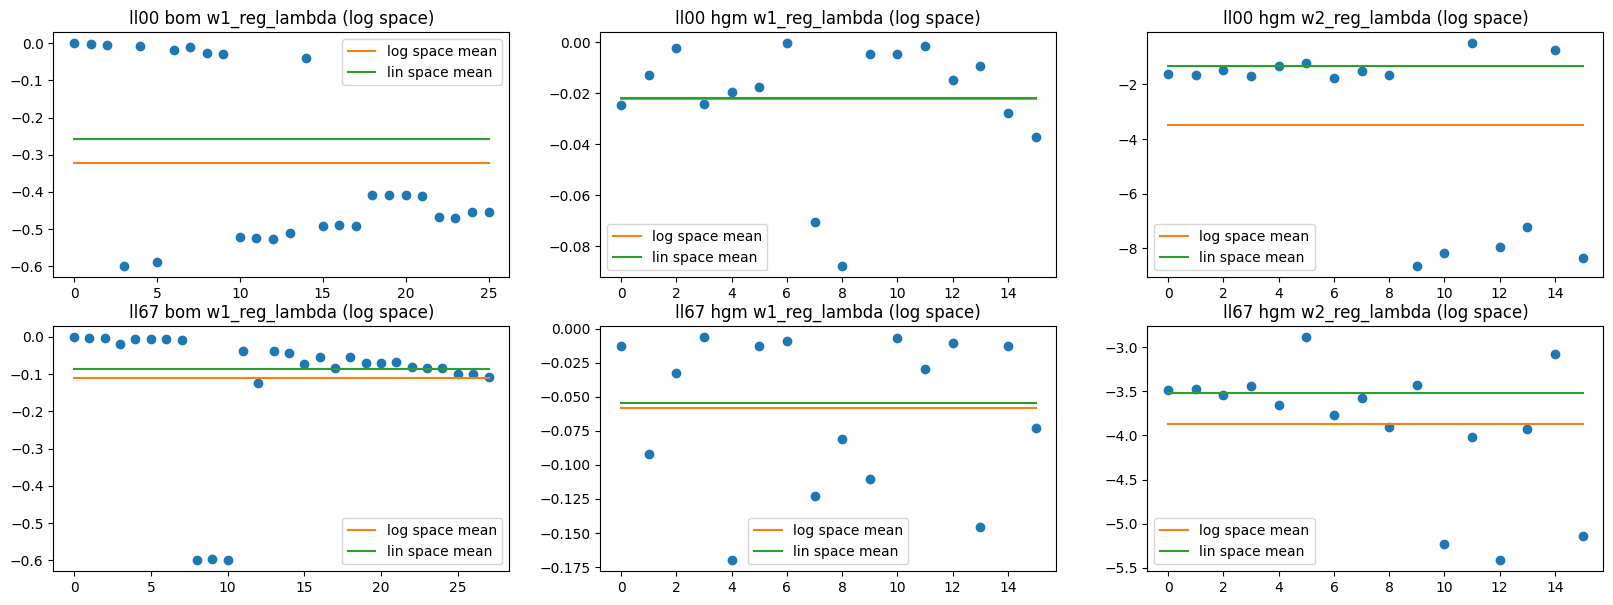

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(20, 7))
idx = 0
for ll in ['ll00', 'll67']:
	for model in ['bom', 'hgm']:
		for param in ['w1_reg_lambda', 'w2_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				means = hyperparams[ll][model][param]['mean']
				values = hyperparams[ll][model][param]['all']
				axes[idx // 3, idx % 3].set_title(f'{ll} {model} {param} (log space)')
				if hist:
					axes[idx // 3, idx % 3].hist(np.log10(values), bins=25)
				else:
					axes[idx // 3, idx % 3].plot(np.log10(values), marker='o', linestyle='None')
					axes[idx // 3, idx % 3].plot(np.repeat(np.mean(np.log10(values)), values.shape[0]), label='log space mean')
					axes[idx // 3, idx % 3].plot(np.repeat(np.log10(np.mean(values)), values.shape[0]), label='lin space mean')
					axes[idx // 3, idx % 3].legend()
				idx += 1
			else:
				continue

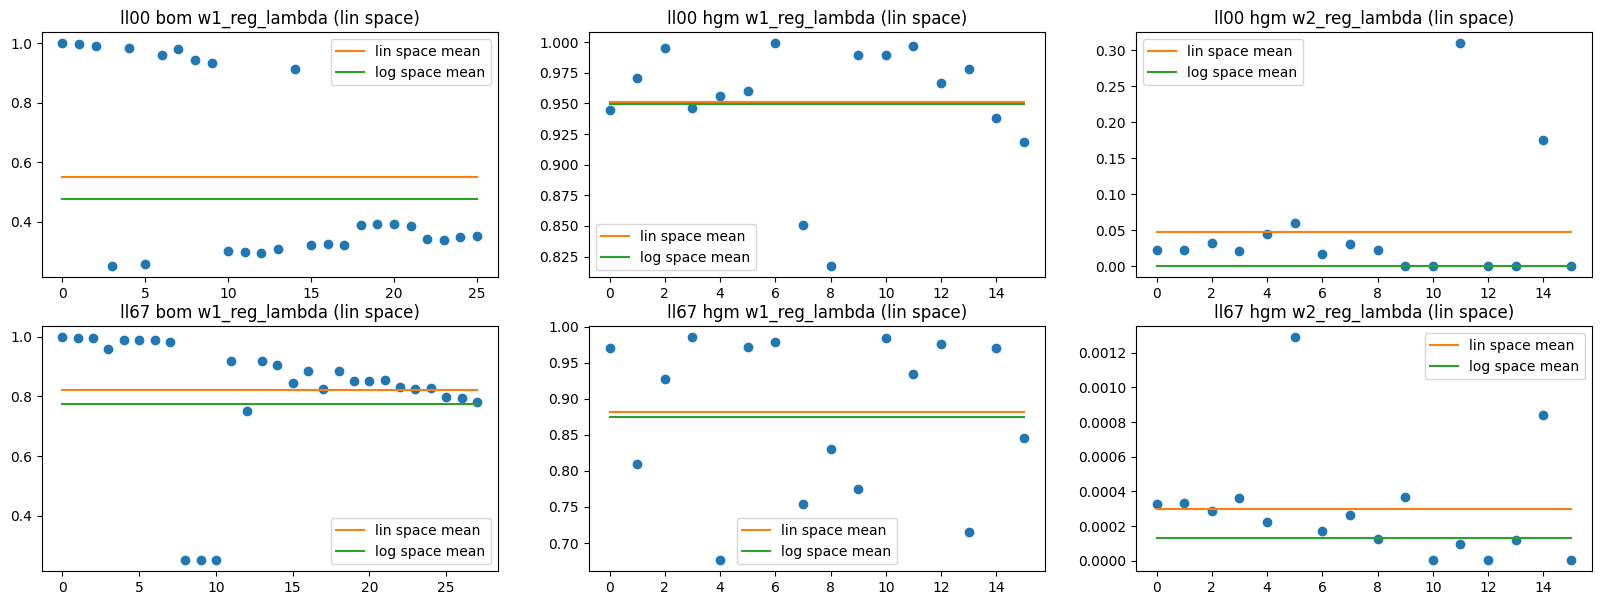

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(20, 7))
idx = 0
for ll in ['ll00', 'll67']:
	for model in ['bom', 'hgm']:
		for param in ['w1_reg_lambda', 'w2_reg_lambda']:
			if param in hyperparams[ll][model].keys():
				means = hyperparams[ll][model][param]['mean']
				values = hyperparams[ll][model][param]['all']
				axes[idx // 3, idx % 3].set_title(f'{ll} {model} {param} (lin space)')
				if hist:
					axes[idx // 3, idx % 3].hist(values, bins=25)
				else:
					axes[idx // 3, idx % 3].plot(values, marker='o', linestyle='None')
					axes[idx // 3, idx % 3].plot(np.repeat(means['linear'], values.shape[0]), label='lin space mean')
					axes[idx // 3, idx % 3].plot(np.repeat(means['geometric'], values.shape[0]), label='log space mean')
					axes[idx // 3, idx % 3].legend()
				idx += 1
			else:
				continue